In [2]:
# Dependencies
%pip install matplotlib numpy
from matplotlib import pyplot
import numpy


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


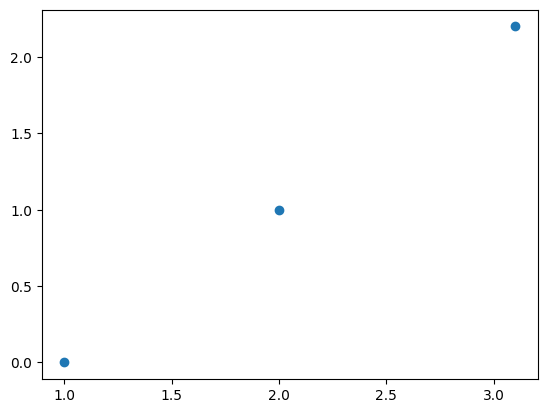

In [9]:
# Make up some knots for which we will interpolate splines.
t = numpy.array([1.,2.,3.1])
y = numpy.array([0.,1.,2.2])
v = numpy.argsort(t)
t = t[v]
y = y[v]
pyplot.scatter(t, y)

In [10]:
# https://fncbook.github.io/fnc/localapprox/splines.html
class Splines:
    def __init__(
        self,
        x: numpy.ndarray,
        y: numpy.ndarray,
    ):
        """Fit cubic not-a-knot splines to the coordinates in x and y.
    
        Args:
            x: vector of x coordinates for knots
            y: vector of matching y coordinates for knots
        """
        
        # Validate arguments.
        if x.ndim != 1:
            raise TypeError('Argument x must be a vector.')
        if y.ndim != 1:
            raise TypeError('Argument y must be a vector.')
        if len(x) < 3:
            raise ValueError("Argument x has length {}, must be at least length 3.".format(len(x)))
        if len(y) < 3:
            raise ValueError("Argument y has length {}, must be at least length 3.".format(len(y)))
        if len(x) != len(y):
            raise ValueError("Argument x has length {} but y has length {}. Lengths must be equal.".format(len(x), len(y)))
    
        # The x coordinates must be in ascending order.
        # Sort the data based on the x coordinates.
        v = numpy.argsort(x)
        x = x[v]
        y = y[v]
        del v
    
        # Compute differences between x coordinates.
        h = numpy.diff(x)
    
        # How many splines do we need to interpolate?
        # Equal to len(x) - 1.
        n = len(h)
    
        # Allocate a matrix and a vector to express 4*n linear constraints.
        A = numpy.zeros((4*n,4*n))
        v = numpy.zeros(4*n)
    
        # Add n constraints for left endpoint interpolation.
        A[0:n, 0:n] = numpy.eye(n)
        v[0:n] = y[0:n]
    
        # Add n constraints for right endpoint interpolation.
        A[n:2*n, 0:n] = numpy.eye(n)
        A[n:2*n, n:2*n] = numpy.diag(h)
        A[n:2*n, 2*n:3*n] = numpy.diag(h**2)
        A[n:2*n, 3*n:4*n] = numpy.diag(h**3)
        v[n:2*n] = y[1:]
    
        # Add n-1 constraints for continuity of first derivative
        J = (numpy.eye(n) + numpy.diag(-numpy.ones(n-1), k=1))[:-1, :]
        A[2*n:3*n-1, n:2*n] = J
        A[2*n:3*n-1, 2*n:3*n] = numpy.diag(2*h)[:-1, :]
        A[2*n:3*n-1, 3*n:4*n] = numpy.diag(3*h**2)[:-1, :]
    
        # Add n-1 constraints for continuity of the second derivative.
        A[3*n-1:4*n-2, 2*n:3*n] = J
        del J
        A[3*n-1:4*n-2, 3*n:4*n] = numpy.diag(3*h)[:-1, :]
    
        # Add two constraints for the not-a-knot condition.
        A[-2, -4] = 1
        A[-2, -3] = -1
        A[-1, -2] = 1
        A[-1, -1] = -1
        
        # Z = numpy.zeros((n, n))
        # In = numpy.eye(n)
        # J = numpy.diag(numpy.ones(n), k=0) + numpy.diag(-numpy.ones(n-1), k=1)
        # H = numpy.diag(h)
        # AL = numpy.hstack((In, Z, Z, Z))
        # vL = y[0:n]
        # AR = numpy.hstack((In, H, H**2, H**3))
        # vR = y[1:]
        # A1 = numpy.hstack((Z[:-1,:], J[:-1,:], 2*H[:-1,:], 3*H[:-1,:]**2))
        # v1 = numpy.zeros(n-1)
        # A2 = numpy.hstack((Z[:-1,:], Z[:-1,:], J[:-1,:], 3*H[:-1,:]))
        # v2 = numpy.zeros(n-1)
        # nakL = numpy.hstack((numpy.zeros((1,3*n)), numpy.array([[1, -1]]), numpy.zeros((1, n-2))))
        # nakR = numpy.hstack((numpy.zeros((1,3*n)), numpy.zeros((1, n-2)), numpy.array([[1, -1]])))
        # A = numpy.vstack((AL, AR, A1, A2, nakL, nakR))
        # v = numpy.hstack((vL, vR, v1, v2, 0, 0))#.reshape(-1,1)
    
        # Solve the linear system.
        # This is roughly equivalent to:
        # v = v.reshape(-1,1)
        # coeffs = numpy.squeeze(numpy.linalg.inv(A).dot(v))
        coeffs = numpy.linalg.solve(A,v)
    
        # Reshape Z into a 4 x n matrix.
        # Each column of Z corresponds to a spline patch in h.
        # Each row of Z corresponds to one of the 4 cubic spline coefficients.
        # Given a coordinate x indexing spline patch k in h, the interpolated y coordinate is:
        # y_interp = coeffs[0,k] + coeffs[1,k]*x + coeffs[2,k]*x**2 + coeffs[3,k]*x**3
        coeffs = coeffs.reshape(4, n)

        # Initialize self.
        self._x = x
        self._y = y
        self._coeffs = coeffs

    @property
    def x(self) -> numpy.ndarray:
        """Return x coordinates of knots.
        """
        return self._x

    @property
    def y(self) -> numpy.ndarray:
        """Return y coordinates of knots.
        """
        return self._y

    @property
    def coeffs(self) -> numpy.ndarray:
        """Return a 4 x n matrix of spline coefficients.

        Each corresponds to a polynomial coefficient from the constant term to the cubic term.
        Each column corresponds to a spline patch from left to right.
        """
        return self._coeffs

    def eval(self, x: numpy.typing.ArrayLike) -> numpy.ndarray:
        """Evaluate the spline interpolation at a vector of x coordinates.
        """
        
        # Validate arguments.
        x = numpy.atleast_1d(x)
        if x.ndim != 1:
            raise TypeError('Argument x must be a vector.')
        for xi in x:
            if xi < self.x[0] or xi > self.x[-1]:
                raise ValueError("x value {} is out of range, must be between x coordinate of first knot {} and last knot {}.".format(xi, self.x[0], self.x[-1]))

        # Map each x coordinate to a patch on the spline.
        k = numpy.zeros(len(x), dtype=numpy.dtype('uint'))
        for i in range(len(x)):
            if x[i] == self.x[0]:
                k[i] = 0
            else:
                k[i] = numpy.squeeze(numpy.argwhere(x[i] <= self.x), axis=1)[0] - 1

        # Convert absolute x to relative x from left knot.
        x = x - self.x[k]

        # Compute the interpolated y coordinates.
        y = self.coeffs[0,k] + self.coeffs[1,k]*x + self.coeffs[2,k]*x**2 + self.coeffs[3,k]*x**3
        return y

[[ 0.          1.        ]
 [ 0.95670996  1.04329004]
 [ 0.04329004  0.04329004]
 [-0.         -0.        ]]


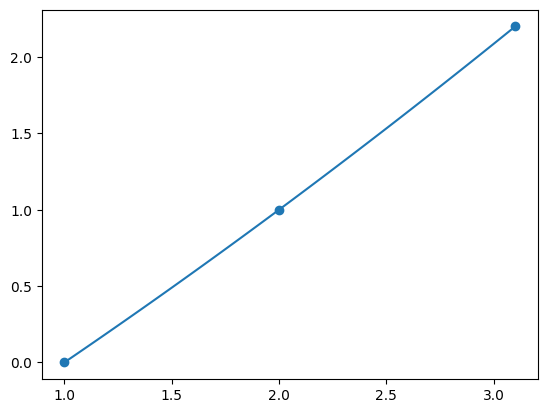

In [11]:
splines = Splines(t, y)
print(splines.coeffs)
x = numpy.linspace(splines.x[0], splines.x[-1], 100)
yinterp = splines.eval(x)
pyplot.scatter(t,y)
pyplot.plot(x,yinterp)